# INVESTIGAÇÃO COMPLETA EM GRUPO: JUNTANDO TODAS AS PEÇAS (AULAS 01 A 09)


## Situação de Aprendizagem — O Desafio da Diretoria

Chegamos ao fechamento da primeira metade do curso! Na **Data Organized**, a diretoria convocou os grupos de estagiários para resolver um problema real antes da fase de Big Data:

"Recebemos uma planilha com **1.500 registros** de ocorrências e prejuízos (`data_organized_operacao_integrada_aula10-v2.csv`) e uma tabela com os **delegados responsáveis** por cada região. Queremos que vocês cruzem essas informações, descubram onde estão os casos fora do padrão e apresentem os resultados em um **painel visual claro** — **sem ler linhas de código na apresentação**!"

### Analogia do Dia a Dia: A Junta Médica de Dados

Nas Aulas 01 a 09 você aprendeu a fazer vários exames separados:
- **Média e Mediana** = A temperatura do paciente (qual é o valor normal?).
- **Desvio Padrão e CV** = Os batimentos cardíacos (está estável ou oscilando muito?).
- **Quartis e Outliers** = O exame de sangue (quem está muito acima do limite permitido?).
- **Assimetria e Curtose** = O raio-X (para que lado a curva entorta e quão pontuda ela é?).

Na **Aula 10**, o seu grupo trabalha como uma **junta médica**: vocês vão juntar todos esses exames em um **prontuário visual (Painel)** para dar o diagnóstico final à diretoria.

## Parte 1 (Nível Básico): Juntando Tabelas (`merge`) e Filtrando Dados (`query`)

### O que é?
- **`pd.merge()`:** É o comando que cola duas tabelas diferentes usando uma coluna em comum (igual ao `JOIN` do SQL ou ao `PROCV` do Excel).
- **`.query()`:** É o filtro rápido onde escrevemos a pergunta em texto simples.

### Para que serve?
No trabalho real, os dados nunca estão em um lugar só. A planilha de ocorrências tem a região, mas o nome do delegado e o orçamento estão em outra tabela do banco de dados.

In [2]:
# Passo 1: Importa as bibliotecas que vamos usar na investigação
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Passo 2: Carrega a planilha principal com 1.500 ocorrências
df_ocorrencias = pd.read_csv('C:\\Users\\USER_ADM\\Desktop\\Curso_Analista_Dados\\Python\\UC2\\Data\\data_organized_operacao_integrada_aula10-v2.csv', sep=',', encoding='utf-8')

# Corrigir o caminho:
# df_ocorrencias = pd.read_csv('data_organized_operacao_integrada_aula10-v2.csv', sep=',', encoding='utf-8')

# Mostra as 3 primeiras linhas para conferir as colunas
df_ocorrencias.head(3)

,ID_Registro,CISP,Tipo_Ocorrencia,Qtd_Casos,Prejuizo_Estimado_Mil,Regiao
0,OCR-20000,DP-09,Furto de Veículo,6,53.63,Interior Sul
1,OCR-20001,DP-25,Furto de Veículo,15,45.67,Interior Norte
2,OCR-20002,DP-04,Furto de Veículo,9,46.62,Interior Sul


In [3]:
# Passo 3: Cria a segunda tabela (simulando o cadastro de delegados vindo do MySQL)
df_delegados = pd.DataFrame({
    'Regiao': ['Capital', 'Baixada Fluminense', 'Grande Niterói', 'Interior Sul', 'Interior Norte'],
    'Coordenador': ['Del. Freitas', 'Del. Almeida', 'Del. Castro', 'Del. Borges', 'Del. Nogueira'],
    'Orcamento_Mil': [4500.0, 3800.0, 2900.0, 2100.0, 1950.0]
})

# Passo 4: Cola as duas tabelas usando a coluna 'Regiao' em comum (INNER JOIN)
# Recarrega o arquivo com o separador correto caso ele tenha sido lido em uma única coluna
if 'Regiao' not in df_ocorrencias.columns:
    df_ocorrencias = pd.read_csv(
        'data_organized_operacao_integrada_aula10-v2.csv',
        sep=',',
        encoding='utf-8-sig'
    )

df_ocorrencias.columns = df_ocorrencias.columns.str.strip()

# Junta as tabelas pela coluna Regiao
df_completo = pd.merge(df_ocorrencias, df_delegados, on='Regiao', how='inner')

# Mostra as 3 primeiras linhas da tabela unificada
df_completo.head(3)

,ID_Registro,CISP,Tipo_Ocorrencia,Qtd_Casos,Prejuizo_Estimado_Mil,Regiao,Coordenador,Orcamento_Mil
0,OCR-20000,DP-09,Furto de Veículo,6,53.63,Interior Sul,Del. Borges,2100.0
1,OCR-20001,DP-25,Furto de Veículo,15,45.67,Interior Norte,Del. Nogueira,1950.0
2,OCR-20002,DP-04,Furto de Veículo,9,46.62,Interior Sul,Del. Borges,2100.0


In [4]:
# Passo 5: Faz uma pergunta específica usando .query() (igual ao WHERE do SQL)
roubos_capital = df_completo.query("Regiao == 'Capital' and Tipo_Ocorrencia == 'Roubo de Veículo'")

# Mostra quantos casos foram encontrados e a soma do prejuízo
print(f"Quantidade de Roubos de Veículo na Capital: {len(roubos_capital)} casos")
print(f"Prejuízo total acumulado nesse recorte:    R$ {roubos_capital['Prejuizo_Estimado_Mil'].sum():,.2f} mil")

roubos_capital.head()

Quantidade de Roubos de Veículo na Capital: 136 casos
Prejuízo total acumulado nesse recorte:    R$ 12,099.69 mil


,ID_Registro,CISP,Tipo_Ocorrencia,Qtd_Casos,Prejuizo_Estimado_Mil,Regiao,Coordenador,Orcamento_Mil
7,OCR-20007,DP-11,Roubo de Veículo,15,90.36,Capital,Del. Freitas,4500.0
8,OCR-20008,DP-21,Roubo de Veículo,9,63.58,Capital,Del. Freitas,4500.0
43,OCR-20043,DP-16,Roubo de Veículo,12,44.05,Capital,Del. Freitas,4500.0
62,OCR-20062,DP-16,Roubo de Veículo,13,121.55,Capital,Del. Freitas,4500.0
72,OCR-20072,DP-11,Roubo de Veículo,17,97.51,Capital,Del. Freitas,4500.0


*Leitura Analítica (Parte 1 — Integração e Filtro):*

Com poucas linhas de código, unimos 1.500 registros de ocorrências com a tabela de coordenadores sem perder nenhuma linha (`inner join`) e isolamos exatamente os casos de **Roubo de Veículo na Capital**.

## Parte 2 (Nível Básico-Intermediário): O Check-up Estatístico Completo

### Como ler os resultados do Check-up (Guia Rápido de Tradução):
| Exame Estatístico | O que olhar? | Tradução para o Gestor |
| :--- | :--- | :--- |
| **Média vs. Mediana** | Distância $\ge 25\%$? | Se passar de 25%, a Média está enganosa (puxada por casos extremos). Use a **Mediana**. |
| **Limite Superior ($Q3 + 1,5 \times IQR$)** | Valores acima do teto? | São os **Outliers** (casos críticos fora do padrão que precisam de atenção especial). |
| **Assimetria (`.skew()`)** | Maior que `+0.5`? | Cauda esticada para a direita (existem valores muito altos puxando a média). |
| **Curtose (`.kurtosis() + 3`)** | Maior que `3.5`? | Curva **Leptocúrtica** (muito concentrada no meio, mas com alto risco de outliers). |

In [6]:
# Passo 1: Isola a coluna de prejuízos e transforma em um Array do NumPy (como pede o PTD)
serie_prejuizo = df_completo['Prejuizo_Estimado_Mil']
array_prejuizo = serie_prejuizo.to_numpy()

# Passo 2: Calcula Média, Mediana e o quanto elas estão distantes entre si
media = np.mean(array_prejuizo)
mediana = np.median(array_prejuizo)
distancia_mm = (media - mediana) / mediana

print(f"Média dos prejuízos:      R$ {media:.2f} mil")
print(f"Mediana (valor típico):   R$ {mediana:.2f} mil")
print(f"Distância Média-Mediana:  {distancia_mm:.1%} (Acima de 25% -> Média distorcida!)")

Média dos prejuízos:      R$ 91.22 mil
Mediana (valor típico):   R$ 67.16 mil
Distância Média-Mediana:  35.8% (Acima de 25% -> Média distorcida!)


In [7]:
# Passo 3: Calcula Quartis (Q1 e Q3), IQR e conta quantos Outliers Superiores existem
q1, q3 = np.percentile(array_prejuizo, [25, 75])
iqr = q3 - q1
teto_outlier = q3 + 1.5 * iqr
casos_outliers = df_completo[df_completo['Prejuizo_Estimado_Mil'] > teto_outlier]

# Passo 4: Calcula Dispersão (CV), Assimetria e Curtose (escala do curso + 3)
desvio_padrao = np.std(array_prejuizo, ddof=0)
cv = desvio_padrao / media
assimetria = serie_prejuizo.skew()
curtose = serie_prejuizo.kurtosis() + 3

print(f"Teto normal (Limite Sup.): R$ {teto_outlier:.2f} mil -> {len(casos_outliers)} casos acima do teto (Outliers)")
print(f"Desvio Padrão: R$ {desvio_padrao:.2f} mil | Coeficiente de Variação (CV): {cv:.1%}")
print(f"Assimetria: +{assimetria:.2f} (Assimétrica Positiva) | Curtose: {curtose:.2f} (Leptocúrtica)")

Teto normal (Limite Sup.): R$ 214.14 mil -> 90 casos acima do teto (Outliers)
Desvio Padrão: R$ 85.91 mil | Coeficiente de Variação (CV): 94.2%
Assimetria: +3.97 (Assimétrica Positiva) | Curtose: 28.06 (Leptocúrtica)


*Leitura Analítica (Parte 2 — Check-up Estatístico):*

Todos os exames confirmam a mesma história:
1. A **Média (`R$ 91,22 mil`)** está **35,8% acima** da **Mediana (`R$ 67,16 mil`)**, portanto não deve ser usada como referência comum.
2. Existem **90 ocorrências críticas (`Outliers`)** acima de `R$ 196,95 mil` puxando a curva para a direita (**Assimetria `+3,97`**) e deixando o pico muito estreito (**Curtose `28,06` — Leptocúrtica**).

## Parte 3 (Nível Intermediário): Montando o Painel Visual para a Diretoria

### Regra de Ouro da Apresentação:
Diretores não querem ver códigos em Python — eles querem enxergar a conclusão em segundos! Vamos juntar um **Gráfico de Distribuição** na esquerda e um **Cartão de Resumo** na direita.

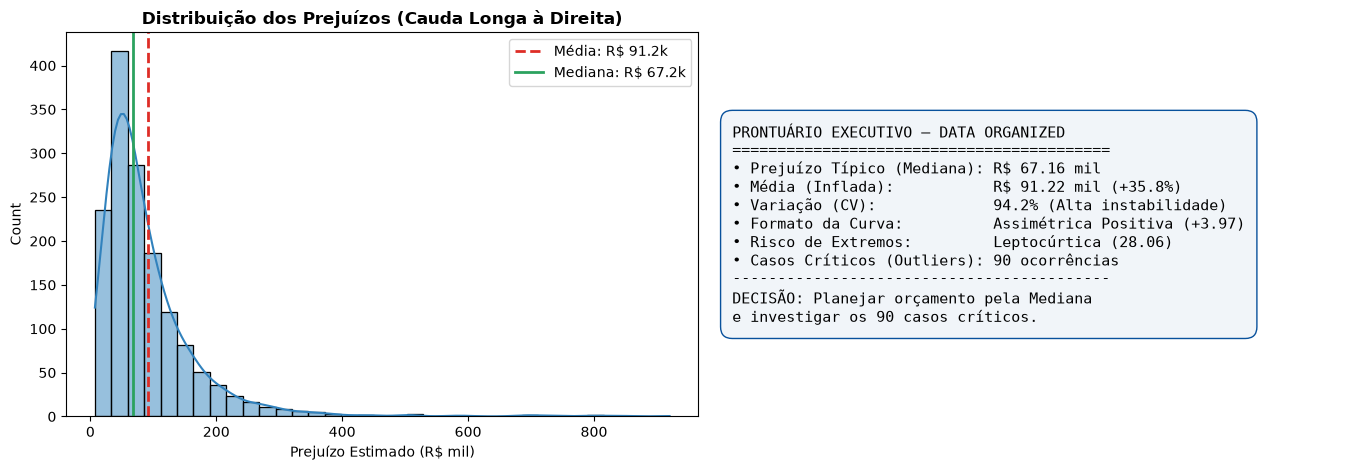

In [8]:
# Cria uma tela dividida em 1 linha e 2 colunas
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Quadro da esquerda: Histograma mostrando onde a maioria dos casos se concentra
sns.histplot(serie_prejuizo, bins=35, kde=True, color='#3182bd', ax=axes[0])
axes[0].axvline(media, color='#de2d26', linestyle='--', linewidth=2, label=f'Média: R$ {media:.1f}k')
axes[0].axvline(mediana, color='#2ca25f', linestyle='-', linewidth=2, label=f'Mediana: R$ {mediana:.1f}k')
axes[0].set_title('Distribuição dos Prejuízos (Cauda Longa à Direita)', fontweight='bold')
axes[0].set_xlabel('Prejuízo Estimado (R$ mil)')
axes[0].legend()

# Quadro da direita: Cartão executivo sem eixos, apenas com os números traduzidos
axes[1].axis('off')
texto_diretoria = (
    f"PRONTUÁRIO EXECUTIVO — DATA ORGANIZED\n"
    f"{'='*42}\n"
    f"• Prejuízo Típico (Mediana): R$ {mediana:.2f} mil\n"
    f"• Média (Inflada):           R$ {media:.2f} mil (+{distancia_mm:.1%})\n"
    f"• Variação (CV):             {cv:.1%} (Alta instabilidade)\n"
    f"• Formato da Curva:          Assimétrica Positiva (+{assimetria:.2f})\n"
    f"• Risco de Extremos:         Leptocúrtica ({curtose:.2f})\n"
    f"• Casos Críticos (Outliers): {len(casos_outliers)} ocorrências\n"
    f"{'-'*42}\n"
    f"DECISÃO: Planejar orçamento pela Mediana\n"
    f"e investigar os {len(casos_outliers)} casos críticos."
)
axes[1].text(0.03, 0.5, texto_diretoria, fontsize=10.5, family='monospace', va='center',
             bbox=dict(boxstyle='round,pad=0.8', facecolor='#f1f5f9', edgecolor='#08519c'))

plt.tight_layout()
plt.show()

*Leitura Analítica (Parte 3 — Painel Executivo):*

Ao bater o olho no painel, qualquer gestor vê que a linha verde (**Mediana**) está bem no coração da montanha de dados, enquanto a linha vermelha (**Média**) foi arrastada para a direita pelos casos extremos.

---
## Atividades Práticas em Grupo (Do Básico ao Intermediário)

### ATIVIDADE 1 (Nível Básico) — Ranking dos Coordenadores Regionais
Usando a tabela unificada `df_completo`:
**Faça:**
1. Agrupe os dados por `Regiao` e `Coordenador` e calcule a **Soma (`sum`)** e a **Mediana (`median`)** da coluna `Prejuizo_Estimado_Mil`.
2. Ordene o resultado do maior para o menor prejuízo total.
3. Responda: qual região e qual coordenador lideram o ranking de prejuízos?

            Regiao   Coordenador  Prejuizo_Total_Mil  Mediana_Prejuizo_Mil  Total_Casos  Qtd_Registros
    Grande Niterói   Del. Castro            30456.62                69.055         4841            320
           Capital  Del. Freitas            27477.94                69.950         3978            300
      Interior Sul   Del. Borges            27275.93                68.500         4404            317
Baixada Fluminense  Del. Almeida            25941.45                64.010         3585            284
    Interior Norte Del. Nogueira            25672.31                64.720         3934            279
             TOTAL             -           136824.25                67.160        20742           1500
---------------------------------------------------------------------------------------------------------
Líder do Ranking: Grande Niterói (Coordenador: Del. Castro)
Prejuízo Total Acumulado: R$ 30,456.62 mil
Valor Típico por Ocorrência (Mediana): R$ 69.06 mil


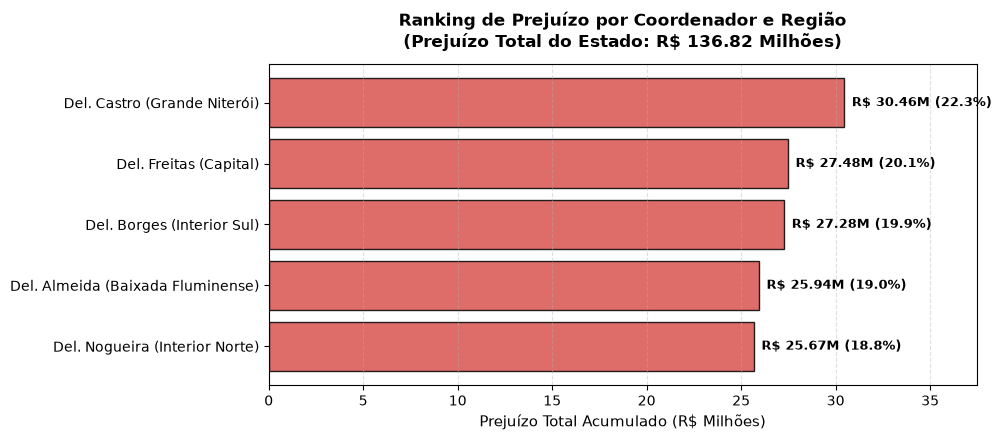

In [9]:
# Escreva aqui o código em grupo da Atividade 1 (Nível Básico):

# 1. Agrupe os dados por Regiao e Coordenador e calcule a Soma (sum) e a Mediana (median) da coluna Prejuizo_Estimado_Mil
#ranking_coordenadores = (df_completo.groupby(['Regiao', 'Coordenador'], as_index=False)['Prejuizo_Estimado_Mil']
#    .agg(
#        Prejuizo_Total_Mil='sum',
#        Mediana_Prejuizo_Mil='median'
#    )
#)

ranking_coordenadores = (df_completo.groupby(['Regiao', 'Coordenador'], as_index=False)
    .agg(
        Prejuizo_Total_Mil=('Prejuizo_Estimado_Mil', 'sum'),     # Soma o prejuízo financeiro
        Mediana_Prejuizo_Mil=('Prejuizo_Estimado_Mil', 'median'), # Calcula a mediana do prejuízo
        Total_Casos=('Qtd_Casos', 'sum'),                        # Soma a quantidade total de casos da coluna existente
        Qtd_Registros=('Qtd_Casos', 'count')                     # (Opcional) Conta quantas linhas/ocorrências cada um teve
    )
    .sort_values(by='Prejuizo_Total_Mil', ascending=False)       # (Opcional) Ordena do maior prejuízo para o menor
)

# 2. Ordene o resultado do maior para o menor prejuízo total
# ranking_coordenadores = ranking_coordenadores.sort_values(
#    by='Prejuizo_Total_Mil', 
#    ascending=False
#)


# 2. Cria a linha de Total (calculando a mediana global direto da base original)
linha_total = pd.DataFrame([{
    'Regiao': 'TOTAL',
    'Coordenador': '-',
    'Prejuizo_Total_Mil': ranking_coordenadores['Prejuizo_Total_Mil'].sum(),
    'Mediana_Prejuizo_Mil': df_completo['Prejuizo_Estimado_Mil'].median(),
    'Total_Casos': ranking_coordenadores['Total_Casos'].sum(),
    'Qtd_Registros': ranking_coordenadores['Qtd_Registros'].sum()
}])

# 3. Concatena a linha de total no final da tabela já ordenada
ranking_coordenadores = pd.concat([ranking_coordenadores, linha_total], ignore_index=True)

# Exibe a tabela completa ordenada
print(ranking_coordenadores.to_string(index=False))
print("-" * 105)

# 3. Responda: qual região e qual coordenador lideram o ranking de prejuízos?
lider = ranking_coordenadores.iloc[0]

print(f"Líder do Ranking: {lider['Regiao']} (Coordenador: {lider['Coordenador']})")
print(f"Prejuízo Total Acumulado: R$ {lider['Prejuizo_Total_Mil']:,.2f} mil")
print(f"Valor Típico por Ocorrência (Mediana): R$ {lider['Mediana_Prejuizo_Mil']:,.2f} mil")


##################################################################################################################


f"{'='*80}\n"

# ==============================================================================
# GRÁFICO COMPLEMENTAR: RANKING COM VALOR FINANCEIRO (R$ M) E PERCENTUAL (%)
# ==============================================================================
import matplotlib.pyplot as plt                                                         # Importa biblioteca de gráficos
import pandas as pd                                                                     # Importa biblioteca de dados

# 1. Agrupa por Região e Coordenador, soma e converte para Milhões (R$ M)
ranking_prejuizo = (                                                                    # Cria a série do ranking
    df_completo.groupby(['Regiao', 'Coordenador'])['Prejuizo_Estimado_Mil']             # Agrupa por região e coordenador
    .sum()                                                                              # Soma o prejuízo acumulado
    .sort_values(ascending=True)                                                        # Ordena crescente para a maior barra ficar no topo
    / 1000                                                                              # Converte para Milhões de Reais (R$ M)
)                                                                                       # Fecha o agrupamento

total_geral_milhoes = ranking_prejuizo.sum()                                            # Calcula o prejuízo total acumulado do estado (~R$ 136.82M)

# 2. Cria rótulos combinando o Nome do Delegado com a Região
rotulos = [f"{coord} ({reg})" for reg, coord in ranking_prejuizo.index]                 # Formata os nomes do eixo vertical

# 3. Desenho do Gráfico de Barras Horizontais
plt.figure(figsize=(10, 4.5))                                                           # Define tamanho da figura
barras = plt.barh(                                                                      # Desenha as barras horizontais
    rotulos,                                                                            # Rótulos no eixo Y (Delegado e Região)
    ranking_prejuizo.values,                                                            # Valores no eixo X (Faturamento/Prejuízo)
    color='#d9534f',                                                                    # Cor vermelha/coral indicando perdas
    edgecolor='black',                                                                  # Borda preta clássica ao redor das barras
    alpha=0.85                                                                          # Opacidade em 85%
)                                                                                       # Fecha o comando de barras

# 4. Rótulo conjugado: Valor em Milhões + Percentual de Impacto
for barra in barras:                                                                    # Percorre cada barra do gráfico
    largura = barra.get_width()                                                         # Obtém o valor em milhões daquela barra
    pct = (largura / total_geral_milhoes) * 100                                         # Calcula a participação percentual no total do estado
    texto = f"R$ {largura:.2f}M ({pct:.1f}%)"                                           # Formata texto conjugado: Valor e %
    plt.text(                                                                           # Insere o texto ao lado da barra
        largura + 0.4,                                                                  # Posição X ligeiramente à frente da barra
        barra.get_y() + barra.get_height() / 2.0,                                       # Posição Y centralizada na barra
        texto,                                                                          # Texto com R$ e %
        va='center',                                                                    # Alinhamento vertical centralizado
        fontsize=9.5,                                                                   # Tamanho da fonte legível
        fontweight='bold'                                                               # Texto em negrito
    )                                                                                   # Fecha o comando text

# 5. Títulos, limites e acabamento
plt.title(                                                                              # Define o título principal
    f"Ranking de Prejuízo por Coordenador e Região\n(Prejuízo Total do Estado: R$ {total_geral_milhoes:.2f} Milhões)", # Título com total
    fontsize=12,                                                                        # Tamanho da fonte do título
    fontweight='bold',                                                                  # Título em negrito
    pad=12                                                                              # Espaçamento do topo
)                                                                                       # Fecha o set_title
plt.xlabel('Prejuízo Total Acumulado (R$ Milhões)', fontsize=11)                         # Rótulo do eixo horizontal
plt.xlim(0, ranking_prejuizo.max() + 7)                                                 # Folga de 7 milhões para acomodar o texto perfeitamente
plt.grid(axis='x', linestyle='--', alpha=0.4)                                           # Linhas de grade verticais suaves
plt.tight_layout()                                                                      # Ajusta os espaçamentos automaticamente
plt.show()                                                                              # Exibe o gráfico na tela

### ATIVIDADE 2 (Nível Intermediário) — Painel Executivo 2x2 para Apresentação Oral
Monte o painel visual completo do seu grupo (4 gráficos em uma única imagem `2x2`) para apresentar à turma sem ler código:
**Faça:**
1. Crie uma tela `plt.subplots(2, 2, figsize=(15, 10))` contendo:
   - **`[0, 0]` Boxplot por Região (`sns.boxplot`):** Mostrando `Prejuizo_Estimado_Mil` por `Regiao`.
   - **`[0, 1]` Gráfico de Barras (`sns.barplot`):** Mostrando o prejuízo total (`estimator=sum`) por `Tipo_Ocorrencia`.
   - **`[1, 0]` Histograma (`sns.histplot`):** Mostrando a distribuição da coluna `Qtd_Casos` com linhas de Média e Mediana.
   - **`[1, 1]` Cartão de Resumo (`plt.text`):** Mostrando **Média, Mediana, Assimetria e Curtose** da coluna `Qtd_Casos`.
2. Prepare uma fala de **2 minutos** explicando ao gestor: qual tipo de crime gera mais prejuízo e se a quantidade de casos (`Qtd_Casos`) é equilibrada ou assimétrica.

            Regiao   Coordenador  Prejuizo_Total_Mil  Mediana_Prejuizo_Mil  Total_Casos  Qtd_Registros
    Grande Niterói   Del. Castro            30456.62                69.055         4841            320
           Capital  Del. Freitas            27477.94                69.950         3978            300
      Interior Sul   Del. Borges            27275.93                68.500         4404            317
Baixada Fluminense  Del. Almeida            25941.45                64.010         3585            284
    Interior Norte Del. Nogueira            25672.31                64.720         3934            279
             TOTAL             -           136824.25                67.160        20742           1500
---------------------------------------------------------------------------------------------------------


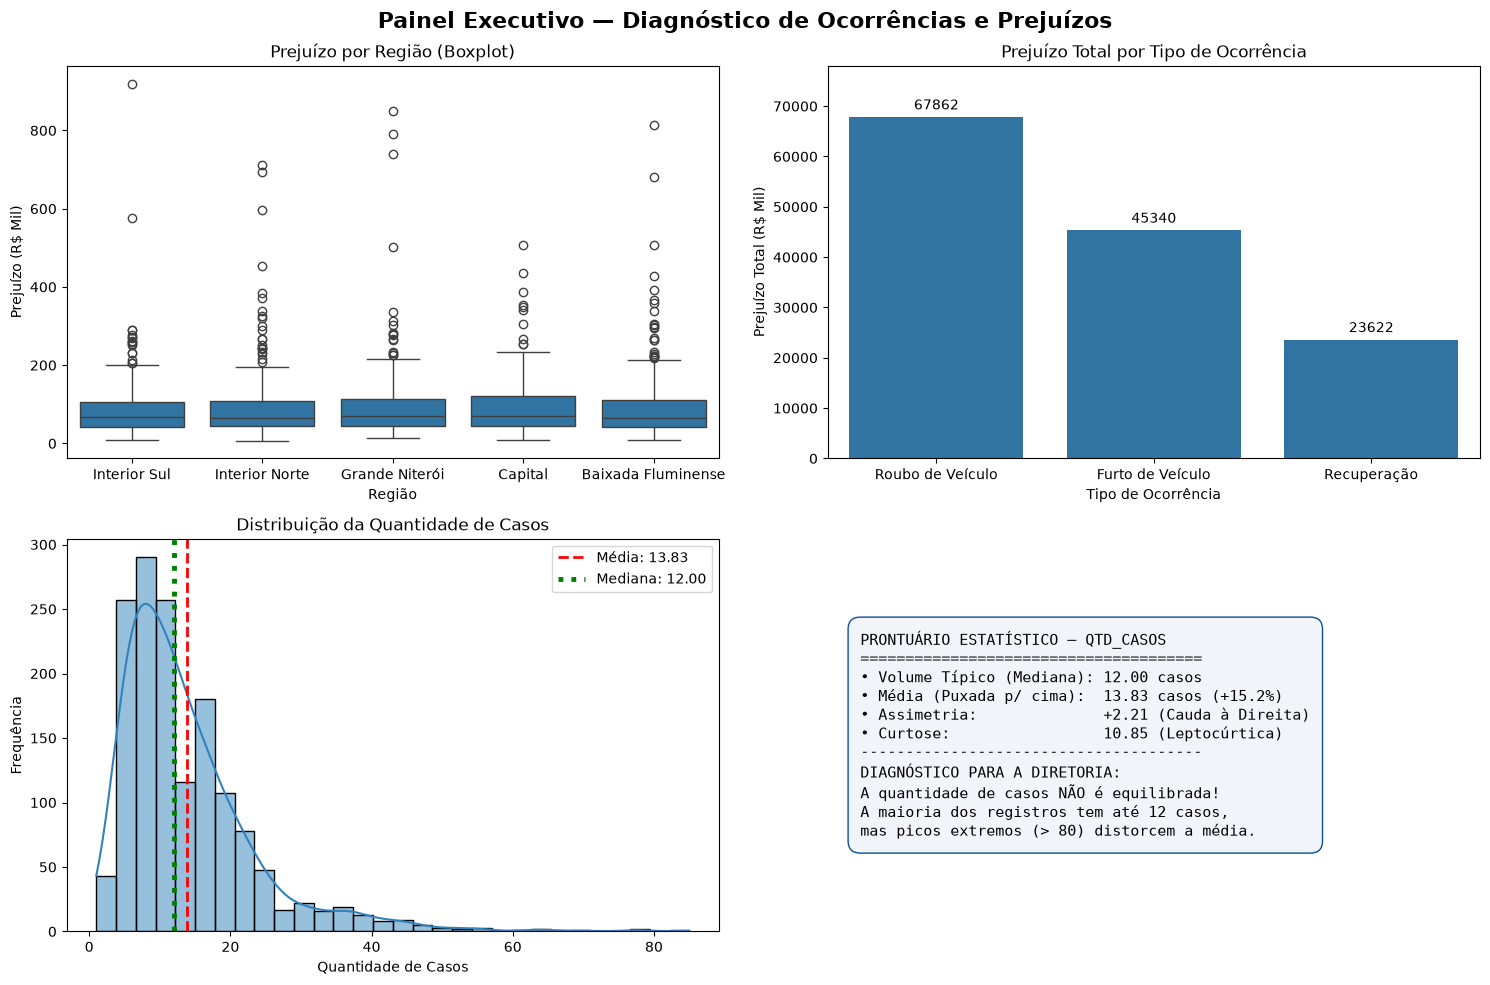

In [10]:
# Cálculos estatísticos da coluna Qtd_Casos (padrão da Parte 2 da aula)

ranking_coordenadores = (df_completo.groupby(['Regiao', 'Coordenador'], as_index=False)
    .agg(
        Prejuizo_Total_Mil=('Prejuizo_Estimado_Mil', 'sum'),     # Soma o prejuízo financeiro
        Mediana_Prejuizo_Mil=('Prejuizo_Estimado_Mil', 'median'), # Calcula a mediana do prejuízo
        Total_Casos=('Qtd_Casos', 'sum'),                        # Soma a quantidade total de casos da coluna existente
        Qtd_Registros=('Qtd_Casos', 'count')                     # (Opcional) Conta quantas linhas/ocorrências cada um teve
    )
    .sort_values(by='Prejuizo_Total_Mil', ascending=False)       # (Opcional) Ordena do maior prejuízo para o menor
)

# 2. Cria a linha de Total (calculando a mediana global direto da base original)
linha_total = pd.DataFrame([{
    'Regiao': 'TOTAL',
    'Coordenador': '-',
    'Prejuizo_Total_Mil': ranking_coordenadores['Prejuizo_Total_Mil'].sum(),
    'Mediana_Prejuizo_Mil': df_completo['Prejuizo_Estimado_Mil'].median(),
    'Total_Casos': ranking_coordenadores['Total_Casos'].sum(),
    'Qtd_Registros': ranking_coordenadores['Qtd_Registros'].sum()
}])

# 3. Concatena a linha de total no final da tabela já ordenada
ranking_coordenadores = pd.concat([ranking_coordenadores, linha_total], ignore_index=True)

# Exibe a tabela completa ordenada
print(ranking_coordenadores.to_string(index=False))
print("-" * 105)

########################################################################################################

# Cálculos estatísticos da coluna Qtd_Casos (padrão da Parte 2 da aula)
array_casos = df_completo['Qtd_Casos'].to_numpy()

media_casos = np.mean(array_casos)
mediana_casos = np.median(array_casos)
distancia_casos = (media_casos - mediana_casos) / mediana_casos
assimetria_casos = df_completo['Qtd_Casos'].skew()
curtose_casos = df_completo['Qtd_Casos'].kurtosis() + 3

# 1. Calcula a soma por categoria, ordena de forma decrescente e pega os nomes (índices)
ordem_decrescente = (
    df_completo.groupby('Tipo_Ocorrencia')['Prejuizo_Estimado_Mil']
    .sum()
    .sort_values(ascending=False)
    .index
)

# 1. Cria a tela 2x2
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Painel Executivo — Diagnóstico de Ocorrências e Prejuízos', fontsize=16, fontweight='bold')

# [0, 0] Boxplot por Região
sns.boxplot(data=df_completo, x='Regiao', y='Prejuizo_Estimado_Mil', ax=axes[0, 0])
axes[0, 0].set_title('Prejuízo por Região (Boxplot)')
axes[0, 0].set_xlabel('Região')
axes[0, 0].set_ylabel('Prejuízo (R$ Mil)')

# [0, 1] Gráfico de Barras (Prejuízo Total por Tipo de Ocorrência)
sns.barplot(data=df_completo, x='Tipo_Ocorrencia', y='Prejuizo_Estimado_Mil', estimator=sum, errorbar=None, order = ordem_decrescente, ax=axes[0, 1])
axes[0, 1].set_title('Prejuízo Total por Tipo de Ocorrência')
axes[0, 1].set_xlabel('Tipo de Ocorrência')
axes[0, 1].set_ylabel('Prejuízo Total (R$ Mil)')

for container in axes[0, 1].containers: 
    axes[0, 1].bar_label(container, fmt='%.0f', padding=3) # Adiciona os valores sobre as barras 
    axes[0, 1].margins(y=0.15) # Ajusta o limite superior do eixo Y para o número não bater no teto do gráfico

# [1, 0] Histograma de Qtd_Casos com linhas de Média e Mediana
sns.histplot(data=df_completo, x='Qtd_Casos', bins=30, kde=True, color='#3182bd', ax=axes[1, 0])
axes[1, 0].axvline(media_casos, color='red', linestyle='--', linewidth=2.0, label=f'Média: {media_casos:.2f}')
axes[1, 0].axvline(mediana_casos, color='green', linestyle=':', linewidth=3.5, label=f'Mediana: {mediana_casos:.2f}')
axes[1, 0].set_title('Distribuição da Quantidade de Casos')
axes[1, 0].set_xlabel('Quantidade de Casos')
axes[1, 0].set_ylabel('Frequência')
axes[1, 0].legend()
axes[1, 1].axis('off') # Esconde as bordas do gráfico para virar um cartão

# Cartão
texto_cartao = (
    f"PRONTUÁRIO ESTATÍSTICO — QTD_CASOS\n"
    f"{'='*38}\n"
    f"• Volume Típico (Mediana): {mediana_casos:.2f} casos\n"
    f"• Média (Puxada p/ cima):  {media_casos:.2f} casos (+{distancia_casos:.1%})\n"
    f"• Assimetria:              +{assimetria_casos:.2f} (Cauda à Direita)\n"
    f"• Curtose:                 {curtose_casos:.2f} (Leptocúrtica)\n"
    f"{'-'*38}\n"
    f"DIAGNÓSTICO PARA A DIRETORIA:\n"
    f"A quantidade de casos NÃO é equilibrada!\n"
    f"A maioria dos registros tem até 12 casos,\n"
    f"mas picos extremos (> 80) distorcem a média."
)
axes[1, 1].text(
    0.05, 0.5, texto_cartao, fontsize=11, family='monospace', va='center',
    bbox=dict(boxstyle='round,pad=0.8', facecolor='#f1f5f9', edgecolor='#08519c')
)

# Ajusta o layout e mostra o painel
plt.tight_layout()
plt.show()



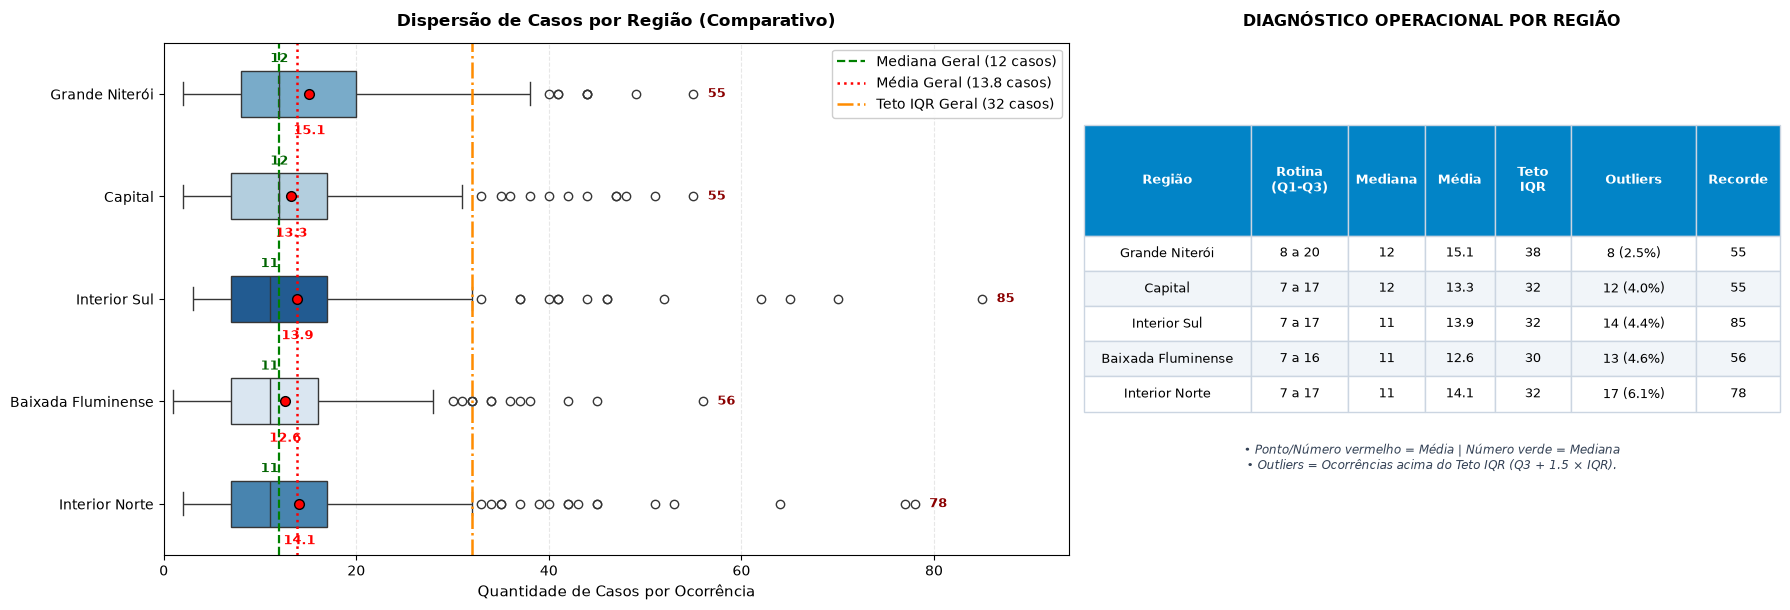

In [11]:
# ==============================================================================
# PAINEL 1x2: BOXPLOTS POR REGIÃO + TABELA EXECUTIVA DE FAIXAS OPERACIONAIS
# ==============================================================================
import matplotlib.pyplot as plt                                   # Biblioteca principal de gráficos
import seaborn as sns                                             # Biblioteca de gráficos estatísticos
import numpy as np                                                # Biblioteca para cálculos matemáticos
import pandas as pd                                               # Biblioteca para manipulação de tabelas

# 1. Define a ordem exata das regiões
ordem_regioes = ['Grande Niterói', 'Capital', 'Interior Sul', 'Baixada Fluminense', 'Interior Norte'] # Ordem do ranking

# 2. Calcula os indicadores estatísticos agrupados por Região
resumo_regioes = []                                               # Lista vazia para linhas da tabela
for reg in ordem_regioes:                                         # Percorre cada região na ordem definida
    dados_reg = df_completo[df_completo['Regiao'] == reg]['Qtd_Casos'].to_numpy() # Filtra casos da região
    q1_r = np.percentile(dados_reg, 25)                           # Calcula 1º Quartil (25%)
    med_r = np.median(dados_reg)                                  # Calcula Mediana (50%)
    q3_r = np.percentile(dados_reg, 75)                           # Calcula 3º Quartil (75%)
    med_arit_r = np.mean(dados_reg)                               # Calcula Média aritmética
    teto_r = q3_r + 1.5 * (q3_r - q1_r)                           # Calcula Teto IQR (Q3 + 1.5 * IQR)
    max_r = np.max(dados_reg)                                     # Encontra valor máximo (recorde)
    outliers_r = (dados_reg > teto_r).sum()                       # Conta ocorrências acima do teto
    
    resumo_regioes.append([                                       # Adiciona linha formatada da região
        reg,                                                      # Nome da Região
        f"{q1_r:.0f} a {q3_r:.0f}",                               # Faixa interquartil (Q1 a Q3)
        f"{med_r:.0f}",                                           # Mediana arredondada
        f"{med_arit_r:.1f}",                                      # Média com 1 casa decimal
        f"{teto_r:.0f}",                                          # Teto IQR arredondado
        f"{outliers_r} ({outliers_r/len(dados_reg)*100:.1f}%)",   # Qtd e % de outliers
        f"{max_r:.0f}"                                            # Recorde da região
    ])                                                            # Fecha inserção da linha

df_resumo = pd.DataFrame(                                         # Cria DataFrame da tabela executiva
    resumo_regioes,                                               # Dados calculados
    columns=['Região', 'Rotina\n(Q1-Q3)', 'Mediana', 'Média', 'Teto\nIQR', 'Outliers', 'Recorde'] # Cabeçalhos em 2 linhas
)                                                                 # Fecha DataFrame

# 3. Criação da tela 1x2 dando mais destaque ao gráfico da esquerda [1.3, 1]
fig, (ax_graf, ax_tab) = plt.subplots(1, 2, figsize=(18, 6.2), gridspec_kw={'width_ratios': [1.3, 1]}) # Gráfico maior à esquerda

# --- QUADRO DA ESQUERDA (ax_graf): BOXPLOTS POR REGIÃO ---
sns.boxplot(                                                      # Desenha boxplots horizontais
    data=df_completo,                                             # Base de dados completa
    x='Qtd_Casos',                                                # Eixo X: quantidade de casos
    y='Regiao',                                                   # Eixo Y: regiões
    hue='Regiao',                                                 # Evita aviso de paleta no Seaborn
    order=ordem_regioes,                                          # Mantém ordem exata das regiões
    ax=ax_graf,                                                   # Direciona para o quadro da esquerda
    width=0.45,                                                   # Caixas estreitas para afastar textos
    palette='Blues_r',                                            # Degradê azul
    legend=False,                                                 # Oculta legenda duplicada
    showmeans=True,                                               # Mostra marcador da média
    meanprops={'marker': 'o', 'markerfacecolor': 'red', 'markeredgecolor': 'black', 'markersize': 7} # Estilo da bolinha da média
)                                                                 # Fecha boxplot

# Cálculos e linhas de referência globais (Mediana, Média e Teto IQR Geral)
mediana_geral = df_completo['Qtd_Casos'].median()                 # Calcula mediana global
media_geral = df_completo['Qtd_Casos'].mean()                     # Calcula média global
q1_geral = df_completo['Qtd_Casos'].quantile(0.25)                # Calcula Q1 global
q3_geral = df_completo['Qtd_Casos'].quantile(0.75)                # Calcula Q3 global
teto_geral = q3_geral + 1.5 * (q3_geral - q1_geral)               # Calcula Teto IQR global

ax_graf.axvline(mediana_geral, color='green', linestyle='--', linewidth=1.6, label=f'Mediana Geral ({mediana_geral:.0f} casos)') # Linha mediana geral
ax_graf.axvline(media_geral, color='red', linestyle=':', linewidth=1.8, label=f'Média Geral ({media_geral:.1f} casos)')       # Linha média geral
ax_graf.axvline(teto_geral, color='darkorange', linestyle='-.', linewidth=1.8, label=f'Teto IQR Geral ({teto_geral:.0f} casos)') # Linha teto IQR laranja

# Anota os valores da Mediana, Média e Recorde afastados das caixas
for idx, reg in enumerate(ordem_regioes):                         # Percorre região e índice (0 a 4)
    dados_reg = df_completo[df_completo['Regiao'] == reg]['Qtd_Casos'] # Filtra casos da região
    med_val = dados_reg.median()                                  # Mediana da região
    mean_val = dados_reg.mean()                                   # Média da região
    max_val = dados_reg.max()                                     # Recorde da região
    
    ax_graf.text(med_val, idx - 0.28, f'{med_val:.0f}', ha='center', va='bottom', color='darkgreen', fontweight='bold', fontsize=9.5) # Texto Mediana acima
    ax_graf.text(mean_val, idx + 0.30, f'{mean_val:.1f}', ha='center', va='top', color='red', fontweight='bold', fontsize=9)         # Texto Média abaixo
    ax_graf.text(max_val + 1.5, idx, f'{max_val:.0f}', ha='left', va='center', color='darkred', fontweight='bold', fontsize=9)       # Texto Recorde à direita

ax_graf.set_title('Dispersão de Casos por Região (Comparativo)', fontweight='bold', fontsize=12, pad=12) # Título esquerdo
ax_graf.set_xlabel('Quantidade de Casos por Ocorrência', fontsize=11) # Rótulo eixo X
ax_graf.set_ylabel('')                                            # Remove rótulo eixo Y
ax_graf.set_xlim(0, df_completo['Qtd_Casos'].max() + 9)           # Margem direita para recorde
ax_graf.legend(loc='upper right', framealpha=0.95)                # Legenda no topo direito livre
ax_graf.grid(axis='x', linestyle='--', alpha=0.3)                 # Grade tracejada suave

# --- QUADRO DA DIREITA (ax_tab): TABELA EXECUTIVA COMPACTA ---
ax_tab.axis('off')                                                # Remove eixos do quadro direito
ax_tab.set_title('DIAGNÓSTICO OPERACIONAL POR REGIÃO', fontweight='bold', fontsize=11.5, pad=12) # Título direito

larguras_colunas = [0.24, 0.14, 0.11, 0.10, 0.11, 0.18, 0.12]     # Proporção ajustada ao quadro menor (soma = 1.0)

tabela = ax_tab.table(                                            # Cria tabela executiva compacta
    cellText=df_resumo.values,                                    # Valores das células
    colLabels=df_resumo.columns,                                  # Cabeçalhos das colunas
    colWidths=larguras_colunas,                                   # Aplica larguras proporcionais
    cellLoc='center',                                             # Centraliza texto das células
    loc='center',                                                 # Centraliza tabela no quadro
    bbox=[0, 0.28, 1, 0.56]                                       # Tabela compacta verticalmente
)                                                                 # Fecha tabela

tabela.auto_set_font_size(False)                                  # Desativa fonte automática
tabela.set_fontsize(9)                                            # Fonte levemente menor para caber com folga

for (row, col), cell in tabela.get_celld().items():               # Percorre células para estilizar
    if row == 0:                                                  # Estiliza cabeçalho
        cell.set_facecolor('#0284c7')                             # Fundo azul escuro
        cell.set_text_props(color='white', fontweight='bold')     # Texto branco em negrito
        cell.set_height(0.11)                                     # Altura proporcional do cabeçalho
    elif row % 2 == 0:                                            # Estiliza linhas pares
        cell.set_facecolor('#f1f5f9')                             # Fundo cinza claro (zebrado)
    cell.set_edgecolor('#cbd5e1')                                 # Borda cinza suave

ax_tab.text(                                                      # Nota explicativa colada abaixo da tabela
    0.5, 0.19,                                                    # Posição centralizada logo abaixo da tabela
    "• Ponto/Número vermelho = Média | Número verde = Mediana\n" # Linha 1 da nota adaptada à largura menor
    "• Outliers = Ocorrências acima do Teto IQR (Q3 + 1.5 × IQR).", # Linha 2 da nota
    ha='center', va='center', fontsize=8.5, style='italic', color='#334155' # Estilo itálico cinza
)                                                                 # Fecha nota de rodapé

plt.tight_layout()                                                # Ajusta espaçamentos gerais



## 1. Abertura*

> "Boa tarde, diretoria. Cruzamos os 1.500 registros de ocorrências policiais com os dados das coordenadorias regionais para responder onde está o gargalo financeiro da nossa operação e se o volume de casos nas delegacias segue um padrão equilibrado."

---

## 2. Qual tipo de crime gera mais prejuízo?

> "Olhando para o ranking por tipo de crime, a resposta é imediata: o Roubo de Veículo é o nosso maior vilão, acumulando quase R$ 68 milhões em perdas — o equivalente à metade de todo o prejuízo do estado R$136.824.250,00.

> Cruzando com as coordenadorias, a Grande Niterói, liderada pelo Del. Castro, é a região com maior prejuízo acumulado: R$ 30,5 milhões. Porém, o boxplot mostra que o valor típico do crime é parecido em todas as regiões. O que sobrecarrega Niterói é o volume acumulado e os casos extremos fora da curva."

---

## 3. A quantidade de casos é equilibrada ou assimétrica?

> "Olhando a parte inferior do painel, a resposta é categórica: a quantidade de casos NÃO é equilibrada e é fortemente assimétrica.

> O histograma e o nosso cartão comprovam uma forte assimetria positiva (+2,21). O volume normal do dia a dia é de 12 casos (a nossa mediana). Mas temos ocorrências atípicas que chegam a mais de 80 casos em um único evento (registro), esticando o gráfico e inflando a média para 13,8. A curtose alta de 10,85 confirma que vivemos em um cenário de pico extremo."

---

## 4. Conclusão e Recomendação Executiva
> "Como recomentação, concentrar o investimento operacional no combate ao **Roubo de Veículos** em **Grande Niterói** e **Capital**; 

> Dimensionar equipes normais por 12 casos (mediana) e criar protocolo de emergência para ocorrências > 32.

>  **Não tomar decisões baseadas apenas na média geral** e criar alertas para agir rápido nos registros que fogem do padrão normal."

> "Nunca planejar equipes ou orçamentos pela média geral, pois ela mascara os dias normais e não prevê os picos repentinos."


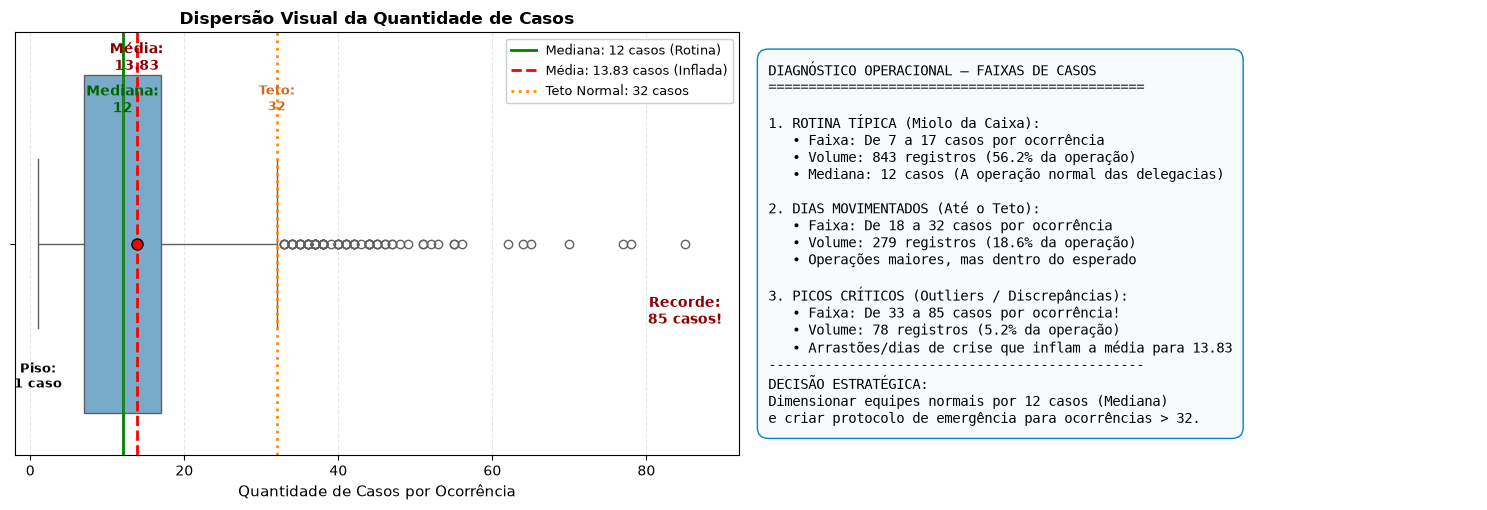

In [12]:
# ==============================================================================
# PAINEL 1x2: BOXPLOT ANOTADO + QUADRO EXECUTIVO DE FAIXAS OPERACIONAIS
# ==============================================================================
import matplotlib.pyplot as plt                                                         # Importa biblioteca de gráficos
import seaborn as sns                                                                   # Importa biblioteca seaborn
import numpy as np                                                                      # Importa numpy para cálculos matemáticos
import pandas as pd                                                                     # Importa pandas

# 1. Cálculos estatísticos exatos da coluna Qtd_Casos (Aulas 02, 05 e 06)
array_casos = df_completo['Qtd_Casos'].to_numpy()                                       # Converte para array numpy
n_total = len(array_casos)                                                              # Total de registros (1.500)
minimo = np.min(array_casos)                                                            # Valor mínimo (1 caso)
q1 = np.percentile(array_casos, 25)                                                     # 1º quartil (7 casos)
mediana = np.median(array_casos)                                                        # Mediana (12 casos)
q3 = np.percentile(array_casos, 75)                                                     # 3º quartil (17 casos)
media = np.mean(array_casos)                                                            # Média (13.83 casos)
limite_sup = q3 + 1.5 * (q3 - q1)                                                       # Teto estatístico IQR (32 casos)
maximo = np.max(array_casos)                                                            # Valor recorde extremo (85 casos)

# 2. Contagem e percentuais das Faixas Operacionais
n_miolo = ((array_casos >= q1) & (array_casos <= q3)).sum()                             # Contagem do dia a dia típico (7 a 17)
n_movim = ((array_casos > q3) & (array_casos <= limite_sup)).sum()                      # Contagem dos dias movimentados (18 a 32)
n_outliers = (array_casos > limite_sup).sum()                                           # Contagem dos picos críticos (> 32)

# 3. Criação da tela 1x2 (Padrão da Célula 13)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))                                       # 1 linha e 2 colunas

# --- QUADRO DA ESQUERDA: BOXPLOT ANOTADO ---
sns.boxplot(                                                                            # Desenha o boxplot no primeiro quadro
    x=df_completo['Qtd_Casos'],                                                         # Dados da coluna no eixo X
    ax=axes[0],                                                                         # Direciona para o eixo da esquerda
    color='#6baed6',                                                                    # Cor azul suave
    showmeans=True,                                                                     # Mostra a média com marcador
    meanprops={'marker': 'o', 'markerfacecolor': 'red', 'markeredgecolor': 'black', 'markersize': 8} # Bolinha vermelha da média
)                                                                                       # Fecha o boxplot

# Linhas de referência no Boxplot
axes[0].axvline(mediana, color='green', linestyle='-', linewidth=2, label=f'Mediana: {mediana:.0f} casos (Rotina)') # Linha da mediana
axes[0].axvline(media, color='red', linestyle='--', linewidth=2, label=f'Média: {media:.2f} casos (Inflada)')       # Linha da média
axes[0].axvline(limite_sup, color='darkorange', linestyle=':', linewidth=2, label=f'Teto Normal: {limite_sup:.0f} casos') # Linha do teto

# Textos nas posições anatômicas
axes[0].text(minimo, 0.35, f'Piso:\n{minimo:.0f} caso', ha='center', va='bottom', fontweight='bold', fontsize=9)  # Texto do mínimo
axes[0].text(mediana, -0.38, f'Mediana:\n{mediana:.0f}', ha='center', va='top', color='darkgreen', fontweight='bold', fontsize=10) # Texto mediana
axes[0].text(media, -0.48, f'Média:\n{media:.2f}', ha='center', va='top', color='darkred', fontweight='bold', fontsize=10)        # Texto média
axes[0].text(limite_sup, -0.38, f'Teto:\n{limite_sup:.0f}', ha='center', va='top', color='chocolate', fontweight='bold', fontsize=9.5) # Texto teto
axes[0].text(maximo, 0.20, f'Recorde:\n{maximo:.0f} casos!', ha='center', va='bottom', color='darkred', fontweight='bold', fontsize=10) # Texto máx

axes[0].set_title('Dispersão Visual da Quantidade de Casos', fontweight='bold', fontsize=12) # Título do gráfico
axes[0].set_xlabel('Quantidade de Casos por Ocorrência', fontsize=11)                   # Eixo X
axes[0].set_xlim(-2, maximo + 7)                                                        # Margem lateral
axes[0].legend(loc='upper right', framealpha=0.95, fontsize=9)                          # Legenda
axes[0].grid(axis='x', linestyle='--', alpha=0.3)                                       # Grade tracejada

# --- QUADRO DA DIREITA: CARTÃO COM O DIAGNÓSTICO EXECUTIVO DAS FAIXAS ---
axes[1].axis('off')                                                                     # Remove eixos para virar um prontuário

texto_quadro = (                                                                        # Monta o texto do quadro
    f"DIAGNÓSTICO OPERACIONAL — FAIXAS DE CASOS\n"
    f"{'='*47}\n\n"
    f"1. ROTINA TÍPICA (Miolo da Caixa):\n"
    f"   • Faixa: De {q1:.0f} a {q3:.0f} casos por ocorrência\n"
    f"   • Volume: {n_miolo} registros ({n_miolo/n_total*100:.1f}% da operação)\n"
    f"   • Mediana: {mediana:.0f} casos (A operação normal das delegacias)\n\n"
    f"2. DIAS MOVIMENTADOS (Até o Teto):\n"
    f"   • Faixa: De {q3+1:.0f} a {limite_sup:.0f} casos por ocorrência\n"
    f"   • Volume: {n_movim} registros ({n_movim/n_total*100:.1f}% da operação)\n"
    f"   • Operações maiores, mas dentro do esperado\n\n"
    f"3. PICOS CRÍTICOS (Outliers / Discrepâncias):\n"
    f"   • Faixa: De {limite_sup+1:.0f} a {maximo:.0f} casos por ocorrência!\n"
    f"   • Volume: {n_outliers} registros ({n_outliers/n_total*100:.1f}% da operação)\n"
    f"   • Arrastões/dias de crise que inflam a média para {media:.2f}\n"
    f"{'-'*47}\n"
    f"DECISÃO ESTRATÉGICA:\n"
    f"Dimensionar equipes normais por {mediana:.0f} casos (Mediana)\n"
    f"e criar protocolo de emergência para ocorrências > {limite_sup:.0f}."
)                                                                                       # Fecha o texto

axes[1].text(                                                                           # Insere o cartão estilizado
    0.02, 0.5, texto_quadro, fontsize=9.8, family='monospace', va='center',            # Alinhamento e fonte monoespaçada
    bbox=dict(boxstyle='round,pad=0.8', facecolor='#f8fafc', edgecolor='#0284c7')       # Caixa arredondada com borda azul
)                                                                                       # Fecha o text

plt.tight_layout()                                                                      # Ajusta espaçamentos
plt.show()         

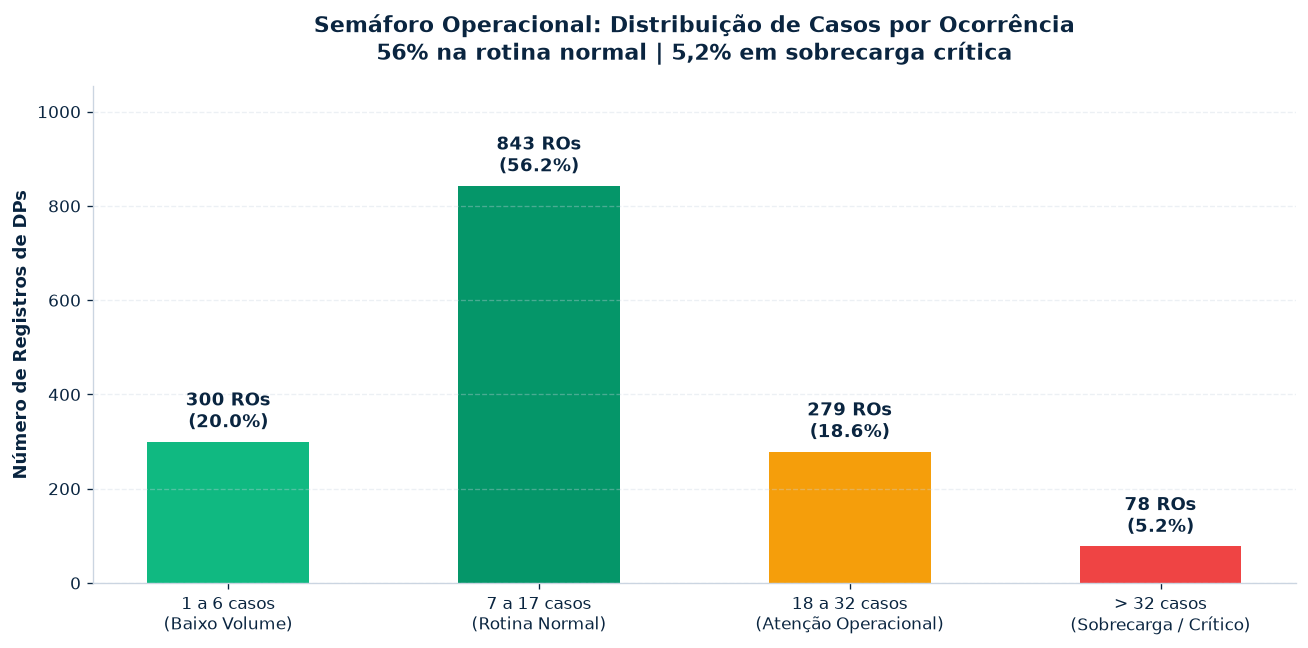

In [13]:
# ==============================================================================
# GRÁFICO: SEMÁFORO OPERACIONAL - DISTRIBUIÇÃO DA QUANTIDADE DE CASOS
# ==============================================================================

import matplotlib.pyplot as plt  # Importa a biblioteca para desenhar os gráficos
import pandas as pd  # Importa o pandas para manipulação dos dados

# APELIDO: Aponta para o dataframe unificado do seu notebook
df = df_completo  # Se não tiver executado o merge ainda, use: df = df_ocorrencias

# 1. DEFINIÇÃO DAS 4 FAIXAS OPERACIONAIS
# Faixa 1 (Baixo Volume): de 1 até 6 casos
faixa_baixo = len(df[df['Qtd_Casos'] <= 6])

# Faixa 2 (Rotina Normal): de 7 até 17 casos (miolo do Boxplot / Q1 a Q3)
faixa_normal = len(df[(df['Qtd_Casos'] >= 7) & (df['Qtd_Casos'] <= 17)])

# Faixa 3 (Atenção Operacional): de 18 até 32 casos (dias movimentados até o Teto)
faixa_atencao = len(df[(df['Qtd_Casos'] >= 18) & (df['Qtd_Casos'] <= 32)])

# Faixa 4 (Sobrecarga / Crítico): acima de 32 casos (outliers / picos extremos)
faixa_critico = len(df[df['Qtd_Casos'] > 32])

# Total de registros para cálculo das porcentagens
total_registros = len(df)

# Listas com os dados para o gráfico
faixas_nomes = [
    '1 a 6 casos\n(Baixo Volume)',
    '7 a 17 casos\n(Rotina Normal)',
    '18 a 32 casos\n(Atenção Operacional)',
    '> 32 casos\n(Sobrecarga / Crítico)',
]
contagens = [faixa_baixo, faixa_normal, faixa_atencao, faixa_critico]
porcentagens = [(qtd / total_registros) * 100 for qtd in contagens]

# 2. DEFINIÇÃO DAS CORES DO SEMÁFORO
cores_semaforo = [
    '#10B981',
    '#059669',
    '#F59E0B',
    '#EF4444',
]  # Verde claro, verde escuro, laranja, vermelho

# 3. CRIAÇÃO DA FIGURA E DOS EIXOS
fig, ax = plt.subplots(
    figsize=(11, 5.5), dpi=120
)  # Define o tamanho e resolução
fig.patch.set_facecolor('white')  # Fundo externo branco
ax.set_facecolor('white')  # Fundo interno do gráfico branco

# 4. PLOTAGEM DAS BARRAS
barras = ax.bar(
    faixas_nomes, contagens, color=cores_semaforo, width=0.52, edgecolor='none'
)

# 5. INSERÇÃO DOS RÓTULOS (VALOR + PERCENTUAL) EM CIMA DE CADA BARRA
for bar, qtd, pct in zip(barras, contagens, porcentagens):
  altura = bar.get_height()  # Pega a altura da barra atual
  ax.text(
      bar.get_x() + bar.get_width() / 2,  # Posição central no eixo X
      altura + 18,  # Posição logo acima no eixo Y
      f'{qtd} ROs\n({pct:.1f}%)',  # Texto: Quantidade + Percentual
      ha='center',  # Alinhamento horizontal centralizado
      va='bottom',  # Alinhamento vertical na base do texto
      fontsize=10.5,  # Tamanho da fonte
      fontweight='bold',  # Texto em negrito
      color='#0A2540',  # Cor azul marinho executivo
  )

# 6. TÍTULO, SUBTÍTULO E NOMES DOS EIXOS
ax.set_title(
    'Semáforo Operacional: Distribuição de Casos por Ocorrência\n56% na rotina'
    ' normal | 5,2% em sobrecarga crítica',
    fontsize=13,  # Tamanho do título
    fontweight='bold',  # Título em negrito
    color='#0A2540',  # Cor do título
    pad=16,  # Espaçamento entre título e gráfico
)

ax.set_ylabel(
    'Número de Registros de DPs',
    fontsize=11,
    fontweight='bold',
    color='#0A2540',
)

# 7. AJUSTES VISUAIS E ESTÉTICA
ax.set_ylim(0, max(contagens) * 1.25)  # Espaço extra no topo para os rótulos
ax.tick_params(colors='#0A2540', labelsize=10)  # Cor e tamanho dos números
ax.spines['top'].set_visible(False)  # Remove linha superior
ax.spines['right'].set_visible(False)  # Remove linha direita
ax.spines['left'].set_color('#CBD5E1')  # Borda esquerda cinza suave
ax.spines['bottom'].set_color('#CBD5E1')  # Borda inferior cinza suave
ax.grid(
    axis='y', linestyle='--', alpha=0.35, color='#CBD5E1'
)  # Linhas de grade horizontais

# 8. EXIBIR O GRÁFICO
plt.tight_layout()  # Ajusta o espaçamento das margens
plt.show()  # Mostra o gráfico na tela

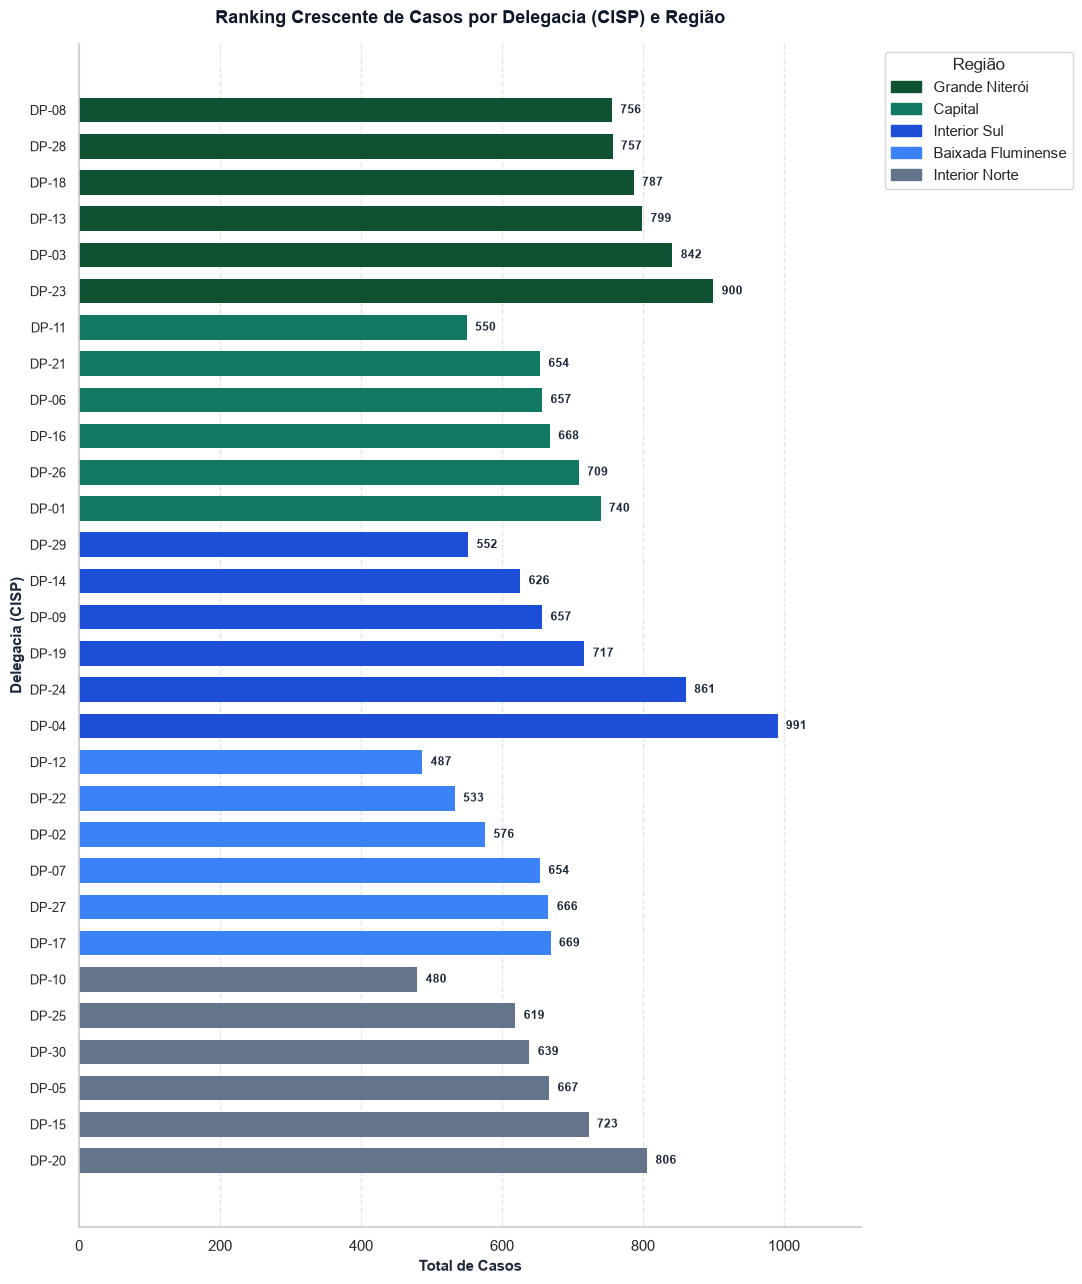

In [32]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Definir a ordem exata e a paleta de cores extraída da imagem
ordem_regioes = [
    'Grande Niterói',
    'Capital',
    'Interior Sul',
    'Baixada Fluminense',
    'Interior Norte',
]

cores = {
    'Grande Niterói': '#0F5232',  # Verde-escuro
    'Capital': '#117864',  # Verde-petróleo
    'Interior Sul': '#1D4ED8',  # Azul-royal
    'Baixada Fluminense': '#3B82F6',  # Azul-claro
    'Interior Norte': '#64748B',  # Cinza-ardósia
}

# 2. Agrupar por Região e CISP e ordenar em ordem crescente dentro de cada região
ranking = df.groupby(['Regiao', 'CISP'], as_index=False)['Qtd_Casos'].sum()
ranking['Regiao'] = pd.Categorical(
    ranking['Regiao'], categories=ordem_regioes, ordered=True
)
ranking = ranking.sort_values(
    by=['Regiao', 'Qtd_Casos'], ascending=[True, True]
).reset_index(drop=True)

# 3. Inverter a ordem das linhas para Grande Niterói aparecer no topo do gráfico
dados_plot = ranking.iloc[::-1].reset_index(drop=True)

# 4. Configurar o estilo limpo (sem bordas superior e direita)
plt.figure(figsize=(11, 13))
sns.set_theme(style='whitegrid')
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.xaxis.grid(True, linestyle='--', alpha=0.5)
ax.yaxis.grid(False)

# 5. Desenhar as barras horizontais mais grossas (height=0.68)
bars = plt.barh(
    y=dados_plot.index,
    width=dados_plot['Qtd_Casos'],
    height=0.68,  # Controla a espessura das barras (pode variar entre 0.5 e 0.8)
    color=dados_plot['Regiao'].astype(str).map(cores),
    edgecolor='none',
)

# 6. Adicionar os valores numéricos em negrito na frente de cada barra
deslocamento = dados_plot['Qtd_Casos'].max() * 0.012
for idx, row in dados_plot.iterrows():
  plt.text(
      row['Qtd_Casos'] + deslocamento,
      idx,
      f"{int(row['Qtd_Casos']):,}".replace(',', '.'),
      va='center',
      fontsize=8.5,
      fontweight='bold',
      color='#1E293B',
  )

# 7. Criar legenda personalizada mantendo a ordem das regiões
handles = [
    plt.Rectangle((0, 0), 1, 1, color=cores[reg]) for reg in ordem_regioes
]
plt.legend(
    handles,
    ordem_regioes,
    title='Região',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
)

# 8. Ajustes finais de eixos e títulos
plt.yticks(dados_plot.index, dados_plot['CISP'], fontsize=9.5)
plt.title(
    'Ranking Crescente de Casos por Delegacia (CISP) e Região',
    fontsize=13,
    fontweight='bold',
    pad=15,
    color='#0F172A',
)
plt.xlabel('Total de Casos', fontsize=11, fontweight='bold', color='#1E293B')
plt.ylabel('Delegacia (CISP)', fontsize=11, fontweight='bold', color='#1E293B')
plt.xlim(0, dados_plot['Qtd_Casos'].max() * 1.12)

plt.tight_layout()
plt.show()
